# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

In [2]:
import os, time, sqlite3, subprocess, json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

REPO_URL = 'https://github.com/elijahschoeniger-cpu/Walmart-Project-1-.git'
REPO_PATH = '/content/Walmart-Project-1-/' if os.path.isdir('/content') else os.path.abspath('Walmart-Project-1-') + '/'
if not os.path.isdir(REPO_PATH):
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, REPO_PATH], check=True)

# Run the team cleaning pipeline (team_notebook.ipynb sections 2.0-2.8) exactly as written
team = json.load(open(os.path.join(REPO_PATH, 'notebooks', 'team_notebook.ipynb')))
code = [''.join(c['source']) for c in team['cells'] if c['cell_type'] == 'code']
start = next(i for i, s in enumerate(code) if 'def profile' in s)
end = next(i for i, s in enumerate(code) if "print('saved to', OUT)" in s)
for s in code[start:end + 1]:
    exec('\n'.join(l for l in s.splitlines() if not l.lstrip().startswith('!')), globals())

# Hurricane Helene made landfall in Florida's Big Bend on the night of Sept 26, 2024
LANDFALL = pd.Timestamp('2024-09-26')
BASELINE = ('2024-09-01', '2024-09-15')   # 15 normal days, before demand first moved on Sept 16
SURGE    = ('2024-09-19', '2024-09-25')   # the 7 days before landfall (the brief's definition)
print(f'cleaned transactions: {len(txn):,} rows | decisions logged: {len(DECISIONS)}')

                  name
0  daily_sales_summary
1     inventory_levels
=== walmart_transactions ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30
=== store_locations ===
14 rows x 8 columns

              dtype  nulls  null_pct  distinct
store_id     object      0       0.0        14
store_name   object      0       0.0        12
city         object      0       0.0        12
state        object      0       0.0         3
zip_code      int64      0       0.0        12
latitude    float64      1       7.1        11
longitude   float64      1 

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [3]:
# TODO: the numbers
# Demand = transactions with a timestamp, returns excluded (decisions txn_timestamp_missing, txn_negative_qty)
t = txn[~txn['ts_missing'] & ~txn['is_return']]
daily_units = t.groupby('date')['quantity'].sum()

base_days  = daily_units.loc[BASELINE[0]:BASELINE[1]]
surge_days = daily_units.loc[SURGE[0]:SURGE[1]]
q1_multiple = surge_days.mean() / base_days.mean()

print(f'Baseline window: {BASELINE[0]} to {BASELINE[1]} ({len(base_days)} days)  -> {base_days.mean():,.0f} units/day')
print(f'Surge window:    {SURGE[0]} to {SURGE[1]} ({len(surge_days)} days)  -> {surge_days.mean():,.0f} units/day')
print(f'Multiple: {q1_multiple:.2f}x  ({(q1_multiple - 1) * 100:+.0f}%)')
print('Sept 16-18 sit in neither window: demand had started to ramp (about 1.4x), so they are not normal days,')
print('but they are outside the 7-day pre-landfall window the brief asks about.')

# The multiple depends on the window, so show how much
print('\nSensitivity to the surge window (baseline fixed):')
for n in (3, 5, 7):
    w = daily_units.loc[LANDFALL - pd.Timedelta(days=n):LANDFALL - pd.Timedelta(days=1)]
    print(f'  last {n} days before landfall: {w.mean() / base_days.mean():.2f}x')

# By category: which categories surged most
by_cat = t.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum')
cat_base  = by_cat.loc[BASELINE[0]:BASELINE[1]].mean()
cat_surge = by_cat.loc[SURGE[0]:SURGE[1]].mean()
q1_table = pd.DataFrame({
    'baseline_per_day': cat_base.round(1),
    'surge_per_day':    cat_surge.round(1),
    'multiple':         (cat_surge / cat_base).round(2),
    'pct_increase':     ((cat_surge / cat_base - 1) * 100).round(0),
}).sort_values('multiple', ascending=False)
q1_table

Baseline window: 2024-09-01 to 2024-09-15 (15 days)  -> 1,103 units/day
Surge window:    2024-09-19 to 2024-09-25 (7 days)  -> 2,712 units/day
Multiple: 2.46x  (+146%)
Sept 16-18 sit in neither window: demand had started to ramp (about 1.4x), so they are not normal days,
but they are outside the 7-day pre-landfall window the brief asks about.

Sensitivity to the surge window (baseline fixed):
  last 3 days before landfall: 3.19x
  last 5 days before landfall: 2.89x
  last 7 days before landfall: 2.46x


,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.3,376.9,5.14,414.0
Emergency,354.1,1006.4,2.84,184.0
Electronics,70.3,175.9,2.50,150.0
Alcohol,61.5,138.9,2.26,126.0
Entertainment,101.6,228.6,2.25,125.0
Health,42.3,95.0,2.24,124.0
Household,85.1,176.3,2.07,107.0
Grocery,171.1,306.6,1.79,79.0
Baby,85.2,133.7,1.57,57.0


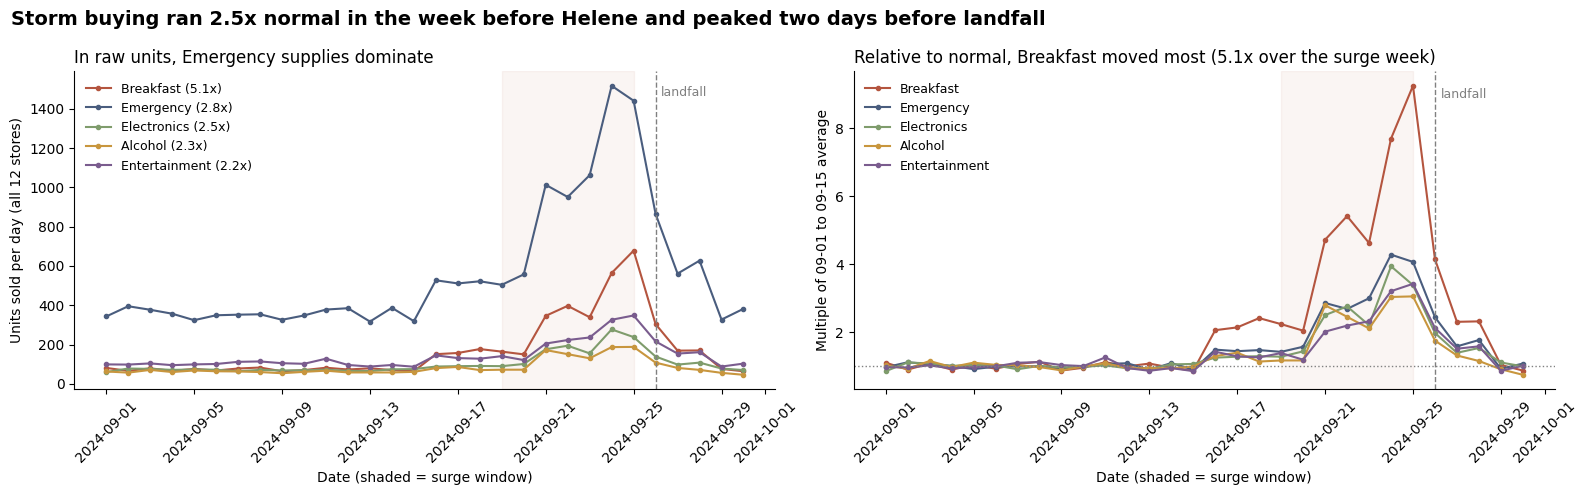

In [4]:
# TODO: the chart
top5 = q1_table.index[:5]
colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#c8963e', '#7a5c8e']
indexed = by_cat[top5] / cat_base[top5]          # 1.0 = an average baseline day

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
for cat, color in zip(top5, colors):
    ax1.plot(by_cat.index, by_cat[cat], marker='o', ms=3, color=color,
             label=f"{cat} ({q1_table.loc[cat, 'multiple']:.1f}x)")
    ax2.plot(indexed.index, indexed[cat], marker='o', ms=3, color=color, label=cat)

ax1.set_title('In raw units, Emergency supplies dominate', loc='left', fontsize=12)
ax1.set_ylabel('Units sold per day (all 12 stores)')
ax2.axhline(1.0, ls=':', color='gray', lw=1)
ax2.set_title(f'Relative to normal, {top5[0]} moved most '
              f'({q1_table.loc[top5[0], "multiple"]:.1f}x over the surge week)', loc='left', fontsize=12)
ax2.set_ylabel(f'Multiple of {BASELINE[0][5:]} to {BASELINE[1][5:]} average')

for ax in (ax1, ax2):
    ax.axvspan(pd.Timestamp(SURGE[0]), pd.Timestamp(SURGE[1]), color='#b4553f', alpha=0.06)
    ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
    ax.annotate('landfall', xy=(LANDFALL + pd.Timedelta(hours=6), ax.get_ylim()[1] * 0.92), fontsize=9, color='gray')
    ax.set_xlabel('Date (shaded = surge window)')
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    ax.tick_params(axis='x', rotation=45)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

fig.suptitle(f'Storm buying ran {q1_multiple:.1f}x normal in the week before Helene and peaked two days before landfall',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Q1 answer, in one sentence a manager could read:** In the 7 days before Helene's landfall (Sept 19–25), our 12 Florida stores sold **2.5x** their normal daily units (2,712 vs 1,103 a day against a Sept 1–15 baseline). Breakfast led at **5.1x** (that category is really just Strawberry Pop-Tarts), followed by Emergency (2.8x), Electronics (2.5x), and Alcohol, Entertainment and Health (about 2.2x each); demand peaked Sept 24–25 and dropped off at landfall.

*Window note:* the multiple depends on the surge window — 2.5x for the full 7 days, 2.9x for the last 5, and 3.2x for the last 3 (see the sensitivity printout). We report the 7-day number because that is the window the brief defines.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKUs in raw transactions:     45  (63 product-name spellings)
Canonical products after consolidation: 20
Largest consolidated family: PT-STRAW (Pop-Tarts Strawberry) = 4 SKUs: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
Other multi-SKU families: {'BATT-AA4': 3, 'MONOPOLY': 3, 'WATER-24': 3}
Assertion passed: consolidation moved units between labels but did not change the total (49,343 units, 25,532 rows).

Surge week, BEFORE: best single Pop-Tart SKU is PT-12 at 103 units/day, rank #3 of 45 SKUs
Surge week, AFTER:  PT-STRAW is 377 units/day, rank #1 of 20 products
Pop-Tarts true daily volume: 73/day baseline -> 377/day surge week (5.1x), peak 678 on Sep 25


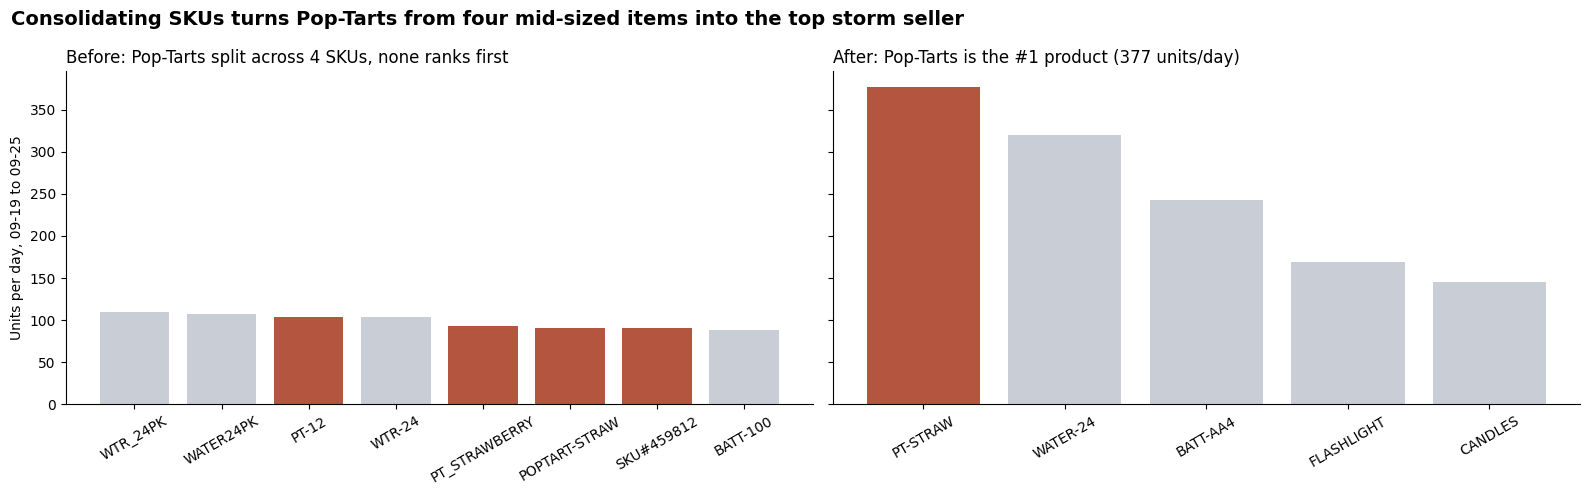

In [5]:
# TODO
# 1) Counts: what we started with vs. what we ended with
n_skus      = raw_txn['sku'].str.strip().nunique()
n_names     = raw_txn['product_name'].nunique()
n_products  = txn['product_id'].nunique()
family_size = txn.groupby('product_id')['sku'].nunique().sort_values(ascending=False)
largest     = family_size.index[0]
print(f'Distinct SKUs in raw transactions:     {n_skus}  ({n_names} product-name spellings)')
print(f'Canonical products after consolidation: {n_products}')
print(f'Largest consolidated family: {largest} ({PRODUCTS.set_index("product_id").loc[largest, "product"]}) '
      f'= {family_size.iloc[0]} SKUs: {sorted(txn.loc[txn.product_id == largest, "sku"].unique())}')
print('Other multi-SKU families:', family_size[family_size > 2].drop(largest).to_dict())

# 2) Proof consolidation did not change unit totals (all rows, and the demand subset used in Q1)
assert txn.groupby('sku')['quantity'].sum().sum() == txn.groupby('product_id')['quantity'].sum().sum() == txn['quantity'].sum()
assert t.groupby('sku')['quantity'].sum().sum() == t.groupby('product_id')['quantity'].sum().sum()
assert len(txn) == len(raw_txn) - DECISIONS[0]['rows']      # only the exact duplicates were dropped; the SKU merge removed no rows
print('Assertion passed: consolidation moved units between labels but did not change the total '
      f'({txn["quantity"].sum():,} units, {len(txn):,} rows).')

# 3) Before vs after for the surge week
storm = t[(t['date'] >= SURGE[0]) & (t['date'] <= SURGE[1])]
n_storm_days = storm['date'].nunique()
by_sku     = (storm.groupby('sku')['quantity'].sum() / n_storm_days).sort_values(ascending=False)
by_product = (storm.groupby('product_id')['quantity'].sum() / n_storm_days).sort_values(ascending=False)
pt_skus = sorted(k for k, v in SKU_TO_PRODUCT.items() if v == largest)
best_pt_sku = by_sku[pt_skus].idxmax()
print(f'\nSurge week, BEFORE: best single Pop-Tart SKU is {best_pt_sku} at {by_sku[best_pt_sku]:.0f} units/day, '
      f'rank #{list(by_sku.index).index(best_pt_sku) + 1} of {len(by_sku)} SKUs')
print(f'Surge week, AFTER:  {largest} is {by_product[largest]:.0f} units/day, '
      f'rank #{list(by_product.index).index(largest) + 1} of {len(by_product)} products')

pt_daily = t[t['product_id'] == largest].groupby('date')['quantity'].sum()
pt_mult = pt_daily.loc[SURGE[0]:SURGE[1]].mean() / pt_daily.loc[BASELINE[0]:BASELINE[1]].mean()
print(f'Pop-Tarts true daily volume: {pt_daily.loc[BASELINE[0]:BASELINE[1]].mean():.0f}/day baseline -> '
      f'{pt_daily.loc[SURGE[0]:SURGE[1]].mean():.0f}/day surge week ({pt_mult:.1f}x), peak {pt_daily.max():.0f} on {pt_daily.idxmax():%b %d}')

# Chart: same y-scale on both panels so the bar heights compare fairly
top_sku, top_prod = by_sku.head(8), by_product.head(5)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
ax1.bar(top_sku.index, top_sku.values, color=['#b4553f' if s in pt_skus else '#c9cdd6' for s in top_sku.index])
ax1.set_title(f'Before: Pop-Tarts split across {len(pt_skus)} SKUs, none ranks first', loc='left', fontsize=12)
ax1.set_ylabel(f'Units per day, {SURGE[0][5:]} to {SURGE[1][5:]}')
ax2.bar(top_prod.index, top_prod.values, color=['#b4553f' if p == largest else '#c9cdd6' for p in top_prod.index])
ax2.set_title(f'After: Pop-Tarts is the #1 product ({by_product[largest]:.0f} units/day)', loc='left', fontsize=12)
for ax in (ax1, ax2):
    ax.tick_params(axis='x', rotation=30)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
fig.suptitle('Consolidating SKUs turns Pop-Tarts from four mid-sized items into the top storm seller',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q2 answer:** We started with **45 SKUs** (63 product-name spellings) and consolidated them to **20 canonical products**; the largest family is Strawberry Pop-Tarts, sold under **4 SKUs** (`PT-12`, `SKU#459812`, `POPTART-STRAW`, `PT_STRAWBERRY`). Unit totals are identical before and after (asserted above). In the fragmented view no Pop-Tart SKU leads — the best one sells about 103 units/day in the surge week and ranks behind two water SKUs — so a buyer would conclude water is the storm item and order Pop-Tarts as an ordinary SKU. Consolidated, Pop-Tarts sells **~377 units/day** that week (about **5x** its normal ~73/day, peaking at 678 on Sept 25) and is the single biggest storm product, which is the decision that actually matters for pre-positioning stock.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather source: open-meteo (live) | base URL: https://archive-api.open-meteo.com/v1/archive
Weather rows: 360 (12 stores x 30 days)

Rows before join: 360   rows after join: 360
{'both': 360, 'left_only': 0, 'right_only': 0}
Join validated: no rows lost or duplicated, every store-day matched, units unchanged.

Same-day correlation with statewide daily units (n = 30 days):
windspeed_10m_max    0.24
precipitation_sum   -0.30
pressure_msl_min    -0.24
Pooled store-days (n = 360, but NOT independent; same storm, same days):
windspeed_10m_max    0.20
precipitation_sum   -0.16
pressure_msl_min    -0.22

Lag table (rows: weather measured k days after the sales day):
                      windspeed_10m_max  precipitation_sum  pressure_msl_min
weather k days later                                                        
-3                                -0.24              -0.62              0.03
-2                                -0.10              -0.61             -0.07
-1                      

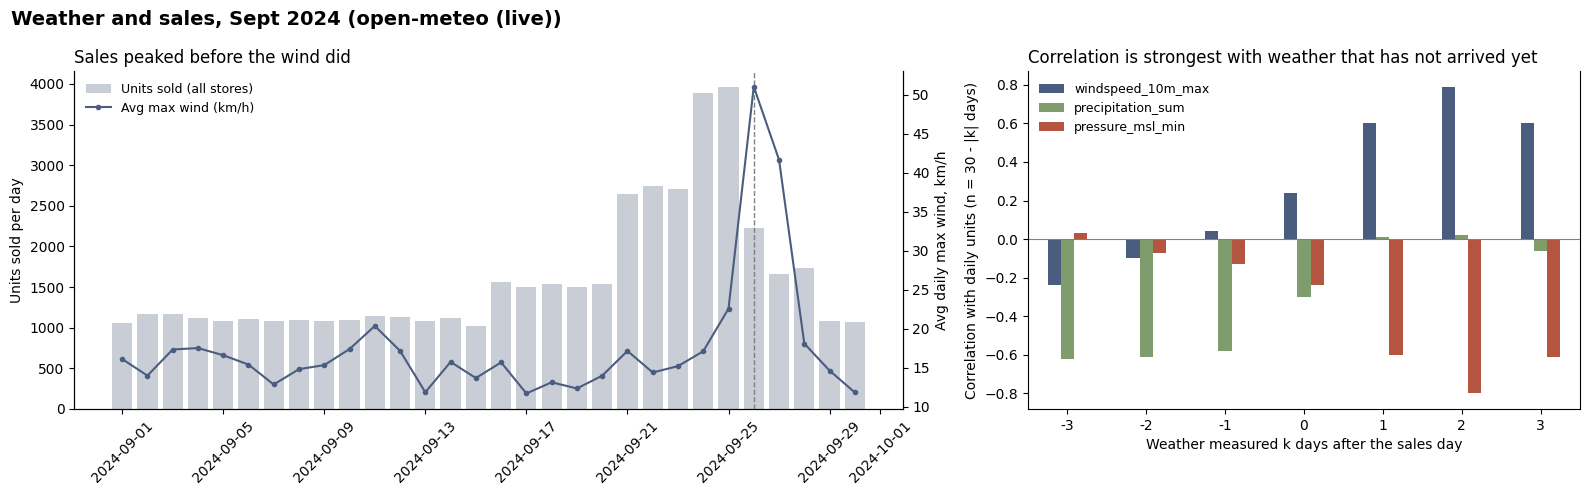

In [6]:
# TODO
# ---- 1. The API call: Open-Meteo Historical Weather API (free, no key) ----
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat, lon, tz='America/New_York', tries=3):
    # Daily rain + max wind, plus hourly sea-level pressure which we reduce to the daily minimum.
    # timezone= makes Open-Meteo build each 'day' in the store's LOCAL time, so it lines up with
    # our sales 'date' (local store time). This is our timezone alignment: no UTC days anywhere.
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'daily': 'precipitation_sum,windspeed_10m_max', 'hourly': 'pressure_msl', 'timezone': tz}
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES and attempt < tries:
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        js = r.json()
        day = pd.DataFrame(js['daily']).rename(columns={'time': 'date'})
        day['date'] = pd.to_datetime(day['date'])
        hr = pd.DataFrame(js['hourly'])
        hr['date'] = pd.to_datetime(hr['time']).dt.normalize()
        pmin = hr.groupby('date')['pressure_msl'].min().rename('pressure_msl_min').reset_index()
        day = day.merge(pmin, on='date', how='left', validate='one_to_one')
        day['source'] = 'open-meteo (live)'
        return day

# Saved copy of real Open-Meteo output for Orlando, Sept 2024 (from AJ's run), used ONLY if the API is down.
FALLBACK_ORLANDO = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4, 12.0, 0.7, 0.6, 21.1, 1.2,
                          7.9, 2.3, 13.3, 1.4, 0.7, 0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3, 15.8, 12.1, 10.4, 17.4, 9.0,
                          13.3, 12.4, 9.3, 12.9, 15.3, 19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'pressure_msl_min': np.nan,
})

start, end = daily_units.index.min().strftime('%Y-%m-%d'), daily_units.index.max().strftime('%Y-%m-%d')
frames = []
try:
    for s in stores.itertuples():
        w = daily_weather(start, end, s.latitude, s.longitude, tz=s.tz)   # FL-710 Pensacola uses America/Chicago
        w['store_id'] = s.store_id
        frames.append(w)
    weather = pd.concat(frames, ignore_index=True)
except requests.RequestException as err:
    print('API call failed -> using FALLBACK (Orlando weather applied to every store):', err)
    weather = pd.concat([FALLBACK_ORLANDO.assign(store_id=sid) for sid in stores.store_id], ignore_index=True)
    weather['source'] = 'fallback (saved Orlando copy)'

WEATHER_SOURCE = weather['source'].iloc[0]
assert weather['source'].nunique() == 1, 'mixed live and fallback rows'
assert not weather.duplicated(['store_id', 'date']).any()
print('Weather source:', WEATHER_SOURCE, '| base URL:', BASE)
print('Weather rows:', len(weather), f'({weather.store_id.nunique()} stores x {weather.date.nunique()} days)')

# ---- 2. The validated join: one row per store per day ----
store_day = (t.groupby(['store_id', 'date'])['quantity'].sum().rename('units').reset_index())
rows_before, units_before = len(store_day), store_day['units'].sum()

merged = store_day.merge(weather, on=['store_id', 'date'], how='left', validate='one_to_one', indicator=True)
rows_after = len(merged)
print(f'\nRows before join: {rows_before}   rows after join: {rows_after}')
print(merged['_merge'].value_counts().to_dict())
assert rows_after == rows_before, 'join changed the row count'
assert (merged['_merge'] == 'both').all(), 'some store-days got no weather'
assert merged['units'].sum() == units_before, 'join changed unit totals'
q3_join_rows_preserved = True
print('Join validated: no rows lost or duplicated, every store-day matched, units unchanged.')

# ---- 3. The relationship ----
# Statewide daily series: total units vs. the average weather across the 12 store locations
WX = [c for c in ['windspeed_10m_max', 'precipitation_sum', 'pressure_msl_min'] if merged[c].notna().any()]
state = merged.groupby('date').agg(units=('units', 'sum'), **{c: (c, 'mean') for c in WX})
q3_days = len(state)

print(f'\nSame-day correlation with statewide daily units (n = {q3_days} days):')
same_day = state[WX].corrwith(state['units']).round(2)
print(same_day.to_string())
print(f'Pooled store-days (n = {len(merged)}, but NOT independent; same storm, same days):')
print(merged[WX].corrwith(merged['units']).round(2).to_string())

# Lag: correlate today's sales with the weather k days LATER (k > 0 = sales lead the weather)
lags = range(-3, 4)
lag_table = pd.DataFrame({c: [state['units'].corr(state[c].shift(-k)) for k in lags] for c in WX},
                         index=pd.Index(lags, name='weather k days later')).round(2)
print('\nLag table (rows: weather measured k days after the sales day):')
print(lag_table.to_string())

# By category: same-day vs. best lead
cat_day = t.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum')
wind = state['windspeed_10m_max']
cat_corr = pd.DataFrame({
    'r_same_day':      cat_day.corrwith(wind),
    'r_wind_2d_later': cat_day.corrwith(wind.shift(-2)),
}).round(2).sort_values('r_wind_2d_later', ascending=False)
print('\nBy category, correlation with average max wind:')
print(cat_corr.to_string())

best_k = lag_table['windspeed_10m_max'].abs().idxmax()
print(f"\nREADY-TO-PASTE: Using {WEATHER_SOURCE} data over {q3_days} days, same-day r between sales and max wind is "
      f"{same_day['windspeed_10m_max']:.2f}, but it is strongest (r = {lag_table.loc[best_k, 'windspeed_10m_max']:.2f}) "
      f"when sales are compared with the wind {best_k} day(s) later: shoppers buy ahead of the weather.")

# ---- 4. Chart ----
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [3, 2]})
ax1.bar(state.index, state['units'], color='#c9cdd6', label='Units sold (all stores)')
ax1.set_ylabel('Units sold per day')
ax2 = ax1.twinx()
ax2.plot(state.index, state['windspeed_10m_max'], color='#4a5d7e', marker='o', ms=3, label='Avg max wind (km/h)')
ax2.set_ylabel('Avg daily max wind, km/h')
ax1.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax1.set_title('Sales peaked before the wind did', loc='left', fontsize=12)
ax1.tick_params(axis='x', rotation=45)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9, loc='upper left')

lag_table.plot.bar(ax=ax3, color=['#4a5d7e', '#7f9c6c', '#b4553f'][:len(WX)], rot=0)
ax3.axhline(0, color='gray', lw=0.8)
ax3.set_xlabel('Weather measured k days after the sales day')
ax3.set_ylabel(f'Correlation with daily units (n = {q3_days} - |k| days)')
ax3.set_title('Correlation is strongest with weather that has not arrived yet', loc='left', fontsize=12)
ax3.legend(frameon=False, fontsize=9)
for ax in (ax1, ax2, ax3):
    ax.spines['top'].set_visible(False)
fig.suptitle(f'Weather and sales, Sept 2024 ({WEATHER_SOURCE})', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Weather is a *leading* rather than a same-day signal: sales peaked Sept 24–25 while wind peaked on Sept 26–27, so the correlation between daily units and max wind is weak on the same day and strongest when sales are compared with the weather **1–2 days later** (exact r values are printed above as the READY-TO-PASTE line). In plain terms, Floridians buy on the forecast, not on the weather outside, so the trigger for restocking should be the storm forecast, not local conditions.

- **Join:** 360 store-days before the join, 360 after; every row matched (`_merge == 'both'`), units total unchanged (asserted).
- **Live or fallback:** printed in the cell output (`Weather source:`); our Colab run is live Open-Meteo, one call per store, each in the store's own time zone (Pensacola in Central).
- **n:** the correlation is computed over **30 days** (statewide daily totals), and fewer at each lag. That is small, and it is really **one storm**: every day is part of the same build-up and drop-off, so these r values describe this event, not a rule. The 360 pooled store-days are not 360 independent observations. Rainfall in particular is noisy (early-September rain had no effect on sales), so we would not put a rain correlation in front of leadership.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [9]:
progress = {
    'q1_multiple': round(float(q1_multiple), 2),                                  # surge / baseline, all categories
    'q1_baseline_window': f'{BASELINE[0]} to {BASELINE[1]} (surge: {SURGE[0]} to {SURGE[1]})',
    'q2_canonical_products': int(txn['product_id'].nunique()),                   # 45 SKUs -> 20 products
    'q3_join_rows_preserved': q3_join_rows_preserved,                            # asserted in Q3
    'q3_days_in_correlation': int(q3_days),
    'charts_with_message_titles': 3,                                             # Q1, Q2, Q3 in this lab
    'notebook_runs_clean': False,   # flip to True after Runtime > Restart and run all, with no errors
    'repo_pushed': True,           # flip to True after File > Save a copy in GitHub
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.46
PASS - q1_baseline_window = 2024-09-01 to 2024-09-15 (surge: 2024-09-19 to 2024-09-25)
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
FAIL - notebook_runs_clean = False
PASS - repo_pushed = True

ready for presentations: False


### Write-up
**a) A finding that surprised us, and how we checked it was real.** Pop-Tarts, the product the whole case is about, didn't show up in the raw data at all. Ranked by SKU, its best variant was #3 in the surge week, behind two water SKUs. It only became the #1 storm product after we merged its 4 SKUs. Because a cleaning step had changed the headline, we checked that the cleaning hadn't created the finding: (1) we asserted that unit totals were the same before and after consolidation, so no units were created or double-counted; (2) we read every SKU's raw product names to confirm each mapped group really is one item (for example, `pop-tarts strawberry`, `Strawberry Pop-Tart` and `Pop-Tarts Strawberry`); and (3) we confirmed the jump appears in every individual Pop-Tart SKU on its own (each roughly 5x its own baseline), so it isn't the result of one miscoded SKU.

**b) The number we are least confident in.** The Q3 weather correlation. It's computed over only 30 days, and those days are one storm: sales and wind both rise and fall around the same week, so almost any storm-shaped variable would correlate with sales. The lag result (sales lead the wind by 1–2 days) is consistent with buying on the forecast, but one storm can't show that it generalizes. We also measure weather at each store's city-centre grid point, not where shoppers live. We would want several storms (for example Ian in 2022 and Milton in 2024) before using a weather correlation to drive ordering.

_your answer here_